# SoilGrids — raw layer fetch for the Study Area

Exploration notebook for the first **Source** of the Bandstack. Decisions
(grilling session 2026-10-12):

- **Scope**: full inventory, mean statistic — 10 properties × 6 depths plus
  `ocs` (0–30 cm only) = **61 layers**
- **Canonical store**: the *native* SoilGrids grid — Interrupted Goode
  Homolosine on a **sphere** (R = 6371000 m), 250 m cells — fetched by
  windowed reads from the published COG VRTs. Not WCS/EPSG:4326
- **Grid stays native**: no alignment, no resampling; single warp happens
  later at bandstack assembly
- **Mask**: Study Area = GISCO NUTS 2021 `BE2` (Flemish Region, excl.
  Brussels), no buffer (open item)
- **Storage**: `data/raw/soilgrids/`, ISRIC filenames, values kept as
  published int16 (decode only for display/analysis)

In [1]:
import json
import urllib.request
from datetime import UTC, datetime
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.crs import CRS
from rasterio.features import geometry_mask
from rasterio.warp import transform as warp_transform
from rasterio.windows import Window, from_bounds

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent

SG_BASE_URL = "https://files.isric.org/soilgrids/latest/data"
SG_CRS = CRS.from_proj4("+proj=igh +R=6371000 +units=m +no_defs")
SG_NODATA = -32768
SG_RES_M = 250.0

NUTS_URL = (
    "https://gisco-services.ec.europa.eu/distribution/v2/nuts/geojson/"
    "NUTS_RG_01M_2021_4326_LEVL_1.geojson"
)
NUTS_ID = "BE2"

DATA_DIR = ROOT / "data" / "raw" / "soilgrids"
GISCO_DIR = ROOT / "data" / "raw" / "gisco"
DATA_DIR.mkdir(parents=True, exist_ok=True)
GISCO_DIR.mkdir(parents=True, exist_ok=True)

DEPTHS = ["0-5", "5-15", "15-30", "30-60", "60-100", "100-200"]
PROPERTIES = ["bdod", "cec", "cfvo", "clay", "nitrogen", "ocd", "phh2o", "sand", "silt", "soc"]
LAYERS = [f"{p}_{d}cm_mean" for p in PROPERTIES for d in DEPTHS] + ["ocs_0-30cm_mean"]

UNITS = {
    "bdod": (100, "g/cm³", "bulk density"),
    "cec": (10, "cmolc/kg", "cation exchange capacity"),
    "cfvo": (1, "g/kg", "coarse fragments"),
    "clay": (1, "g/kg", "clay fraction"),
    "nitrogen": (100, "g/kg", "total nitrogen"),
    "ocd": (10, "g/dm³", "organic carbon density"),
    "ocs": (10, "t/ha", "organic carbon stock"),
    "phh2o": (10, "pH", "pH (H2O)"),
    "sand": (1, "g/kg", "sand fraction"),
    "silt": (1, "g/kg", "silt fraction"),
    "soc": (10, "g/kg", "soil organic carbon"),
}

CITIES = {
    "Brussels": (4.35, 50.85),
    "Leuven": (4.70, 50.88),
    "Ghent": (3.72, 51.05),
    "Antwerp": (4.40, 51.22),
    "Bruges": (3.22, 51.21),
    "Hasselt": (5.34, 50.93),
}

print(f"{len(LAYERS)} layers")
print("native grid:", SG_CRS.to_proj4())

61 layers
native grid: +proj=igh +lon_0=0 +x_0=0 +y_0=0 +R=6371000 +units=m +no_defs=True


## Study Area polygon

GISCO NUTS 2021, scale 1:1M, `BE2` = **Flemish Region** (Brussels is its own
NUTS region `BE1` and excluded — see `CONTEXT.md`). The full LEVL-1 GeoJSON
is cached under `data/raw/gisco/`; the filtered BE2 polygon is kept next to
it as the canonical mask geometry. The polygon — never the raster — is
reprojected to the SoilGrids grid CRS.

Vlaams Gewest — MultiPolygon
bounds (IGH m): [1277527 5602268 1529240 5686979]


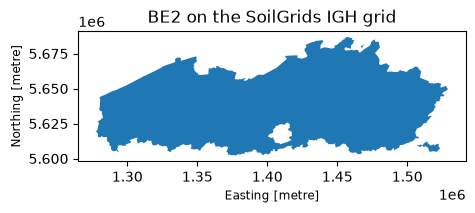

In [2]:
nuts_all_path = GISCO_DIR / "NUTS_RG_01M_2021_4326_LEVL_1.geojson"
if not nuts_all_path.exists():
    urllib.request.urlretrieve(NUTS_URL, nuts_all_path)

nuts_l1 = gpd.read_file(nuts_all_path)
be2 = nuts_l1[nuts_l1["NUTS_ID"] == NUTS_ID]
assert len(be2) == 1, f"expected exactly one {NUTS_ID} feature"

be2_path = GISCO_DIR / "be2_flemish_region_4326.geojson"
if not be2_path.exists():
    be2.to_file(be2_path)

be2_igh = be2.to_crs(SG_CRS)
print(f"{be2.iloc[0]['NAME_LATN']} — {be2_igh.geometry.iloc[0].geom_type}")
print("bounds (IGH m):", np.round(be2_igh.total_bounds).astype(int))

ax = be2_igh.plot(figsize=(5, 8))
ax.set_title(f"{NUTS_ID} on the SoilGrids IGH grid")
plt.show()

## Fetch 61 layers, native grid, masked to the Study Area

One shared integer window (derived from the BE2 bounds) is read from every
VRT — all SoilGrids layers share the same global grid, so the window and
transform are computed once. Pixels whose centre falls outside the polygon
are set to nodata. GDAL HTTP retries are mandatory: transient tile-read
failures occur. Idempotent — existing files are kept unless
`FORCE_REFETCH = True`.

In [3]:
FORCE_REFETCH = False

GDAL_ENV = dict(
    GDAL_HTTP_MAX_RETRY="5",
    GDAL_HTTP_RETRY_DELAY="2",
    GDAL_HTTP_TIMEOUT="60",
    VSI_CACHE="TRUE",
    CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif,.vrt,.ovr",
)


def vrt_url(layer: str) -> str:
    prop = layer.split("_", 1)[0]
    return f"/vsicurl/{SG_BASE_URL}/{prop}/{layer}.vrt"


minx, miny, maxx, maxy = be2_igh.total_bounds
stats = []

with rasterio.Env(**GDAL_ENV):
    with rasterio.open(vrt_url(LAYERS[0])) as src:
        win = from_bounds(minx, miny, maxx, maxy, src.transform).round_offsets().round_lengths()
        win_transform = src.window_transform(win)
    print(
        f"window {int(win.width)}×{int(win.height)} px "
        f"(≈{win.width * SG_RES_M / 1000:.0f}×{win.height * SG_RES_M / 1000:.0f} km)"
    )

    for layer in LAYERS:
        out_path = DATA_DIR / f"{layer}.tif"
        if out_path.exists() and not FORCE_REFETCH:
            with rasterio.open(out_path) as src:
                arr = src.read(1)
        else:
            with rasterio.open(vrt_url(layer)) as src:
                arr = src.read(1, window=win).astype("int16")
            inside = geometry_mask(
                [be2_igh.geometry.iloc[0]],
                out_shape=arr.shape,
                transform=win_transform,
                invert=True,
            )
            arr[~inside] = SG_NODATA
            profile = dict(
                driver="GTiff",
                height=arr.shape[0],
                width=arr.shape[1],
                count=1,
                dtype="int16",
                crs=SG_CRS,
                transform=win_transform,
                nodata=SG_NODATA,
                compress="deflate",
            )
            with rasterio.open(out_path, "w", **profile) as dst:
                dst.write(arr, 1)

        prop = layer.split("_", 1)[0]
        factor, unit, _ = UNITS[prop]
        valid = arr[arr != SG_NODATA]
        stats.append(
            {
                "layer": layer,
                "valid_frac": valid.size / arr.size,
                "raw_min": int(valid.min()),
                "raw_max": int(valid.max()),
                "decoded_mean": float(valid.mean()) / factor,
                "unit": unit,
            }
        )
        print(f"{layer:26s} valid {valid.size / arr.size:6.1%}")

stats_df = pd.DataFrame(stats).set_index("layer")
print(f"\n{len(list(DATA_DIR.glob('*.tif')))} files in {DATA_DIR}")

window 1007×339 px (≈252×85 km)


bdod_0-5cm_mean            valid  52.3%


bdod_5-15cm_mean           valid  52.3%


bdod_15-30cm_mean          valid  52.3%


bdod_30-60cm_mean          valid  52.3%


bdod_60-100cm_mean         valid  52.3%


... (52 outputs left out)

soc_30-60cm_mean           valid  52.3%


soc_60-100cm_mean          valid  52.3%


soc_100-200cm_mean         valid  52.3%


ocs_0-30cm_mean            valid  52.3%

61 files in /home/jfilipovic/projects/TerratwinBE/data/raw/soilgrids


In [4]:
metadata = {
    "source": (
        "SoilGrids 2.0 (ISRIC), 'latest' WebDAV distribution (directory listing dated 2023-02-01)"
    ),
    "fetched_at": datetime.now(UTC).isoformat(timespec="seconds"),
    "base_url": SG_BASE_URL,
    "layer_inventory": LAYERS,
    "statistic": "mean",
    "grid": {
        "crs_proj4": SG_CRS.to_proj4(),
        "resolution_m": SG_RES_M,
        "note": "Interrupted Goode Homolosine on a sphere (R=6371000)",
    },
    "nodata": SG_NODATA,
    "value_encoding": "ISRIC int16, undecoded; per-property factors documented in notebook",
    "mask": {
        "geometry": str(be2_path.relative_to(ROOT)),
        "definition": (
            f"GISCO NUTS 2021 {NUTS_ID} (Flemish Region), 1:1M, EPSG:4326, reprojected to grid CRS"
        ),
        "buffer": "none (open item)",
    },
    "layers_written": sorted(p.name for p in DATA_DIR.glob("*.tif")),
}
with open(DATA_DIR / "_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
print(DATA_DIR / "_metadata.json")

/home/jfilipovic/projects/TerratwinBE/data/raw/soilgrids/_metadata.json


## Sanity checks

1. Per-layer value ranges and valid-pixel fractions (nodata % should track
   the mask, not the data)
2. Known-city pH from the *stored local files* — validates the whole chain
   (sphere-IGH placement, window, mask, write)
3. Texture closure: clay + silt + sand ≈ 1000 g/kg per depth
4. Eyeball maps of pH and SOC at 0–5 cm

In [5]:
stats_df.style.format({"valid_frac": "{:.1%}", "decoded_mean": "{:,.2f}"})

,valid_frac,raw_min,raw_max,decoded_mean,unit
layer,,,,,
bdod_0-5cm_mean,52.3%,90,149,1.25,g/cm³
bdod_5-15cm_mean,52.3%,101,155,1.33,g/cm³
bdod_15-30cm_mean,52.3%,109,166,1.39,g/cm³
bdod_30-60cm_mean,52.3%,107,163,1.48,g/cm³
bdod_60-100cm_mean,52.3%,106,162,1.50,g/cm³
bdod_100-200cm_mean,52.3%,109,163,1.52,g/cm³
cec_0-5cm_mean,52.3%,212,381,26.52,cmolc/kg
cec_5-15cm_mean,52.3%,71,359,17.06,cmolc/kg
cec_15-30cm_mean,52.3%,69,358,15.62,cmolc/kg


In [6]:
def local_median(src, x, y, half=1):
    r, c = src.index(x, y)
    w = Window(c - half, r - half, 2 * half + 1, 2 * half + 1)
    a = src.read(1, window=w)
    v = a[a != SG_NODATA]
    return float(np.median(v)) if v.size else np.nan


lons = [lon for lon, _ in CITIES.values()]
lats = [lat for _, lat in CITIES.values()]
xs, ys = warp_transform("EPSG:4326", SG_CRS, lons, lats)

with rasterio.open(DATA_DIR / "phh2o_0-5cm_mean.tif") as src:
    ph_rows = [
        {"city": name, "pH (H2O) 0-5cm": local_median(src, x, y) / UNITS["phh2o"][0]}
        for (name, _), x, y in zip(CITIES.items(), xs, ys, strict=True)
    ]
pd.DataFrame(ph_rows).set_index("city")

,pH (H2O) 0-5cm
city,
Brussels,NaN
Leuven,4.9
Ghent,5.8
Antwerp,5.5
Bruges,5.9
Hasselt,6.3


In [7]:
texture_rows = []
for depth in DEPTHS:
    fracs = {}
    for prop in ("clay", "silt", "sand"):
        with rasterio.open(DATA_DIR / f"{prop}_{depth}cm_mean.tif") as src:
            fracs[prop] = src.read(1)
    total = fracs["clay"] + fracs["silt"] + fracs["sand"]
    ok = (fracs["clay"] != SG_NODATA) & (fracs["sand"] != SG_NODATA) & (fracs["silt"] != SG_NODATA)
    dev = (total[ok] - 1000.0) / 10.0
    texture_rows.append(
        {
            "depth_cm": depth,
            "n_px": int(ok.sum()),
            "sum_dev_median_pct": float(np.median(dev)),
            "sum_dev_p95_abs_pct": float(np.percentile(np.abs(dev), 95)),
        }
    )
pd.DataFrame(texture_rows).set_index("depth_cm")

,n_px,sum_dev_median_pct,sum_dev_p95_abs_pct
depth_cm,,,
0-5,178629,0.0,0.1
5-15,178629,0.0,0.1
15-30,178629,0.0,0.1
30-60,178629,0.0,0.1
60-100,178629,0.0,0.1
100-200,178629,0.0,0.1


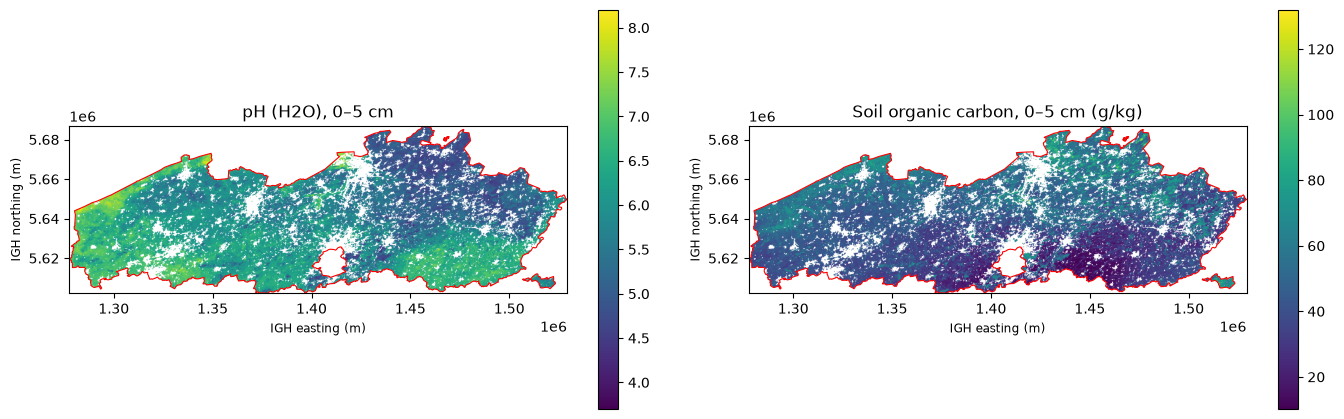

In [8]:
panels = [
    ("phh2o_0-5cm_mean", "phh2o", "pH (H2O), 0–5 cm"),
    ("soc_0-5cm_mean", "soc", "Soil organic carbon, 0–5 cm (g/kg)"),
]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (layer, prop, title) in zip(axes, panels, strict=True):
    factor = UNITS[prop][0]
    with rasterio.open(DATA_DIR / f"{layer}.tif") as src:
        data = src.read(1, masked=True) / factor
        extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)
        im = ax.imshow(data, extent=extent, cmap="viridis")
    be2_igh.boundary.plot(ax=ax, color="red", linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("IGH easting (m)")
    ax.set_ylabel("IGH northing (m)")
    fig.colorbar(im, ax=ax, shrink=0.7)
plt.tight_layout()
plt.show()